# Interactive Hungarian matcher laboratory

**Run the first code cell below to open the live editor.** In VS Code, select this
repository's `.venv` notebook kernel first. This cell works on its own.

- **Move:** click and drag a blue prediction's body.
- **Rotate:** select a box, then drag its yellow circular handle.
- **Resize:** drag its square corner handles.
- **Confidence:** change that prediction's slider under **Independent foreground confidences**.

All ten geometry-only metrics appear simultaneously beside the shared editor.
Click a metric panel to inspect its own matching and cost matrix.
The scene, assignment arrows, and cost matrix update together. Keep the kernel running.
The later **Static reference examples** are saved illustrations; use the live editor here
for mouse interaction.

In [1]:
%matplotlib widget

from IPython.display import display

from ml_sandbox.matcher_lab.presets import baseline, scene_presets
from ml_sandbox.matcher_lab.widgets import MatcherLab

previous_lab = globals().get("lab")
if isinstance(previous_lab, MatcherLab):
    previous_lab.close()
lab = MatcherLab(scene_presets()["Oversized competing prediction"], baseline())
display(lab.view)

## Live laboratory

Click a box body to select and drag it. **Square handles resize along its rotated local axes**,
keeping the opposite corner fixed. **The yellow circle rotates about the center**. Use the
identity dropdown when boxes overlap. Numeric edits apply on Enter or when leaving a field.

Add or remove either type of box; edit each prediction's independent confidence slider.
All ten geometry-only panels solve their **own** Hungarian assignments on the same boxes.
Click a panel, or use **Inspect**, to show that metric's cost matrix and matching in the
large editor. Magenta matrix outlines refer to the **selected metric's assignment**.
**Combined** inspects the separate weighted matcher configured by the checkboxes and sliders.
Changing its weights or confidence leaves the geometry-only comparisons unchanged.
The similarity transform, Gaussian convention, normalization, and Hausdorff samples are shared.
Totals have different units and must not be used to rank metrics.
Pair selectors expose raw values, costs,
and weighted contributions; disabled terms never enter the total.

The minimum side control limits mouse resizing only. Fit scene changes the viewport, preserving
normalization scales. Invalid edits produce a visible message. Motion requests are limited to
30 per second; release always recomputes at the final position. Actual frame rate depends on
scene size and the notebook frontend.

## Static reference examples

These saved SVG diagrams explain the matching objective and remain visible on GitHub.
For dragging, rotation, or confidence edits, use the live editor above.

Hungarian matching finds the cheapest one-to-one assignment **for the supplied cost matrix**.
The examples below show why that objective can prefer different predictions.

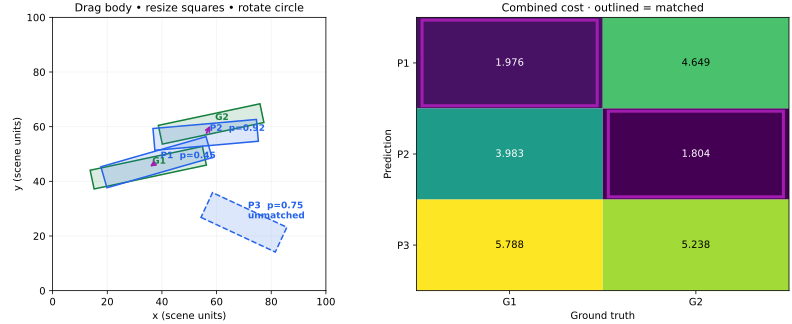

In [2]:
from IPython.display import HTML, SVG, display

from ml_sandbox.matcher_lab import (
    CostTerm,
    MatcherConfig,
    Metric,
    evaluate_costs,
    solve_assignment,
)
from ml_sandbox.matcher_lab.presets import baseline, scene_presets
from ml_sandbox.matcher_lab.visualization import comparison_preview, pair_html, static_preview

scenes = scene_presets()
scene = scenes["Neighboring text lines"]
config = baseline()
display(SVG(static_preview(scene, config)))

Green rectangles are ground truth; blue rectangles are predictions.
Magenta arrows and outlined matrix cells show the **same global assignment**. Dashed boxes
are unmatched. Rows are predictions and columns are targets. A zero-overlap pair can still
be assigned: the solver chooses exactly `min(number of predictions, number of targets)` pairs.

For a concrete confidence tradeoff, use the scene below: P1 has perfect localization but
confidence 0.08; P2 is displaced but has confidence 0.98. The baseline weights geometry enough
to prefer P1. Classification alone prefers P2. These are different objectives, not solver errors.

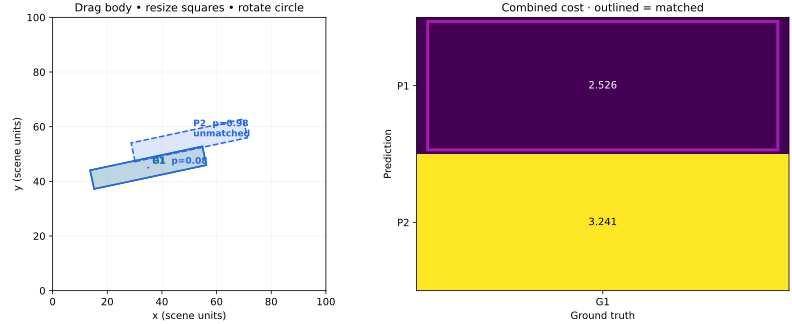

Metric,Raw,Cost,Weighted
L1,0,0,0
Rotated IoU,1,0,0
ProbIoU,1,disabled,0
Hausdorff,0,disabled,0
KL P → GT,0,disabled,0
KL GT → P,0,disabled,0
Symmetric KL (mean),0,disabled,0
Gaussian W2,0,disabled,0
Bhattacharyya,0,disabled,0
Hellinger,0,disabled,0


Metric,Raw,Cost,Weighted
L1,0.25,0.25,1.25
Rotated IoU,0.014692,0.985308,1.97062
ProbIoU,0.106908,disabled,0
Hausdorff,0.180278,disabled,0
KL P → GT,6.39031,disabled,0
KL GT → P,6.39031,disabled,0
Symmetric KL (mean),6.39031,disabled,0
Gaussian W2,18.0278,disabled,0
Bhattacharyya,1.59758,disabled,0
Hellinger,0.893092,disabled,0


In [3]:
tradeoff = scenes["Confidence versus localization"]
geometry_config = baseline()
confidence_config = MatcherConfig((CostTerm(Metric.CLASSIFICATION, 1.0),))
geometry_evaluation = evaluate_costs(tradeoff.predictions, tradeoff.targets, geometry_config)
confidence_evaluation = evaluate_costs(tradeoff.predictions, tradeoff.targets, confidence_config)
assert solve_assignment(geometry_evaluation.total).pairs == ((0, 0),)
assert solve_assignment(confidence_evaluation.total).pairs == ((1, 0),)
display(SVG(static_preview(tradeoff, geometry_config)))
display(HTML(pair_html(tradeoff, geometry_config, geometry_evaluation, "P1", "G1")))
display(HTML(pair_html(tradeoff, geometry_config, geometry_evaluation, "P2", "G1")))

## What enters the matrix?

The explicit Phase 1 baseline is classification × 1 + normalized L1 × 5 + rotated IoU cost × 2.
It is an OBB prototype baseline; standard DETR uses GIoU in its geometry sum. GIoU is deferred.

$$C_{ij}=\sum_k\lambda_k C_k(P_i,G_j),\qquad
\min_{\text{one-to-one pairs}}\sum_{(i,j)}C_{ij}.$$

The notebook keeps the combination and solver call visible:

In [4]:
evaluation = evaluate_costs(scene.predictions, scene.targets, config)
combined_cost = sum(
    (component.weighted for component in evaluation.components),
    start=evaluation.total * 0,
)
assert (combined_cost == evaluation.total).all()
assignment = solve_assignment(combined_cost)
assert len(assignment.pairs) == min(len(scene.predictions), len(scene.targets))
assert len({i for i, _ in assignment.pairs}) == len(assignment.pairs)
assert len({j for _, j in assignment.pairs}) == len(assignment.pairs)

**[L1 (DETR)](https://github.com/facebookresearch/detr/blob/main/models/matcher.py)** sums center and local side-length differences, divided by explicit x/y scene
scales. The default scales are 100 and do not change with zoom. An optional angle term uses the
shortest orientation difference modulo $\pi$, divided by $\pi$; its default weight is zero.
Swapping width and height plus a quarter turn represents the same rectangle but can change
parameter L1. Rotated IoU and Gaussian ProbIoU respect that equivalent geometry.

**[Rotated IoU](https://mmcv.readthedocs.io/en/latest/api/generated/mmcv.ops.box_iou_rotated.html)** uses the actual polygon intersection, including rotated corners. **[ProbIoU](https://arxiv.org/abs/2106.06072)**
represents an OBB with a normalized Gaussian distribution:

$$\Sigma=R_\theta\operatorname{diag}(w^2,h^2)R_\theta^\mathsf{T}/12,\quad
D_B=\tfrac18\Delta c^\mathsf{T}\bar\Sigma^{-1}\Delta c+
\tfrac12\log\frac{\det\bar\Sigma}{\sqrt{\det\Sigma_P\det\Sigma_G}},\quad
S_{\mathrm{ProbIoU}}=1-\sqrt{1-e^{-D_B}}.$$

The implementation evaluates the Gaussian distance with Cholesky solves and computes the
similarity without subtractive cancellation. Finite precision can still underflow at extreme
separation; the configurable epsilon is an explicit floor for logarithmic costs.

Both similarities offer `1 − S` or `−log(max(S, ε))`. L1 remains an unbounded distance.
[Classification NLL](https://docs.pytorch.org/docs/stable/generated/torch.nn.NLLLoss.html) always uses `−log(max(p, ε))`. With one foreground class, classification is
constant across a row: it can decide which predictions remain unmatched when P > G, but cannot
change a square assignment by itself. The two transforms and alternative weights can change
the global assignment when other components are combined.

Original DETR matching uses `-p` for classification; this lab uses negative log probability.
The method reference table below documents the sources and lab-specific adaptations.

## Hausdorff geometry-only matching (WACV 2025)

Choose **Geometry only: Hausdorff** in the live editor. The **Hausdorff points** control
selects 4 corners, 8 corners plus edge midpoints, or 32 boundary samples (8 per edge).
Each direction measures the farthest sampled point's distance to its nearest sample
on the other box. The symmetric distance takes the larger directional result:

$$D_H(A,B)=\max\left(\max_{a\in A}\min_{b\in B}\|a-b\|_2,
                          \max_{b\in B}\min_{a\in A}\|a-b\|_2\right).$$

This is a distance: zero is an identical sampled shape, lower is better, and there
is no upper bound or similarity transformation. Classification is disabled in this
preset. Sampling approximates boundary Hausdorff distance; increasing the point count
can change the cost in either direction. The default four-point mode matches the paper.

Normalization follows RHINO: divide cx/w by **x scale**, cy/h by **y scale**, keep the
angle, then construct the boundary points. Defaults are 100 for both scales. Unequal
scales differ from scaling already-rotated world-space corners. The pair inspector's raw
Hausdorff value is this normalized distance; weight is applied separately.

The constructed **Oversized competing prediction** scene illustrates our screenshot
finding. Compare geometry-only ProbIoU with geometry-only Hausdorff on the same scene.
The saved diagram below uses Hausdorff. In the live editor, vary point count and then
move P1 across the neighboring text lines. A single worst-covered endpoint can dominate
Hausdorff, so test several scenes before deciding that its assignments are preferable.

[Paper §3.4 and sampling ablation](https://arxiv.org/html/2305.07598v5) ·
[Official cost implementation](https://github.com/SIAnalytics/RHINO/blob/main/mmrotate/models/task_modules/assigners/match_cost.py)

This tests one geometric matching term; the full RHINO matcher also includes classification
and KLD. Adaptive denoising and regression-loss changes are outside this experiment.

The saved grid below compares all ten methods on this same scene. Each panel has its own
assignment; dashed boxes are unmatched. ProbIoU with the linear transform and Hellinger
have the same cost mathematically, so matching differences between them indicate numerical ties.


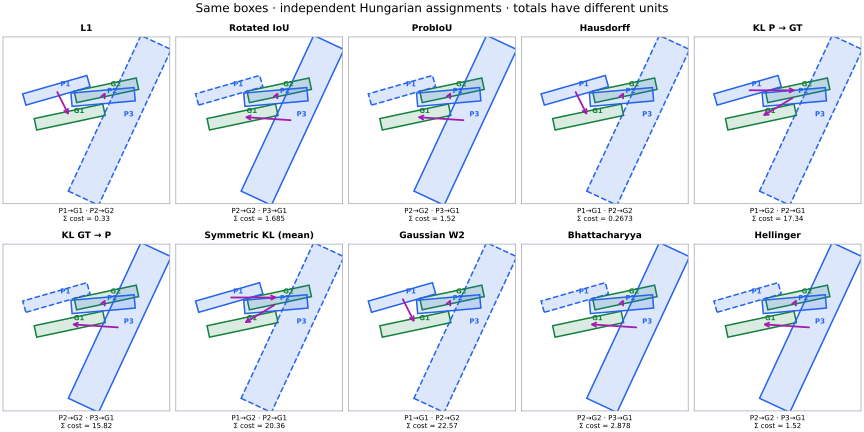

Metric,Raw,Cost,Weighted
L1,0.26,disabled,0
Rotated IoU,0,disabled,0
ProbIoU,6.19728e-05,disabled,0
Hausdorff,0.195765,0.195765,0.195765
KL P → GT,36.8516,disabled,0
KL GT → P,37.9917,disabled,0
Symmetric KL (mean),37.4217,disabled,0
Gaussian W2,17.9153,disabled,0
Bhattacharyya,8.9957,disabled,0
Hellinger,0.999938,disabled,0


In [5]:
hausdorff_scene = scenes["Oversized competing prediction"]
hausdorff_config = MatcherConfig((CostTerm(Metric.HAUSDORFF, 1.0),), hausdorff_points=4)
hausdorff_evaluation = evaluate_costs(
    hausdorff_scene.predictions, hausdorff_scene.targets, hausdorff_config
)
assert solve_assignment(hausdorff_evaluation.total).pairs == ((0, 0), (1, 1))
probiou_config = MatcherConfig((CostTerm(Metric.PROBIOU, 1.0),))
probiou_evaluation = evaluate_costs(
    hausdorff_scene.predictions, hausdorff_scene.targets, probiou_config
)
assert solve_assignment(probiou_evaluation.total).pairs == ((1, 1), (2, 0))
display(SVG(comparison_preview(hausdorff_scene, hausdorff_config)))
display(HTML(pair_html(hausdorff_scene, hausdorff_config, hausdorff_evaluation, "P1", "G1")))

## One controlled experiment

1. Select **Confidence versus localization**. Keep the initial geometry fixed.
2. Disable L1 and rotated IoU. Classification alone selects high-confidence P2.
3. Restore **Reset baseline**. Check which weighted geometry costs overcome that confidence advantage.
4. Try **Class + ProbIoU**, then switch its similarity transform. Inspect both pairs rather than
   comparing totals across different cost definitions as though their scales were identical.
5. With **Neighboring text lines**, move P2 vertically through the gap. Observe the assignment
   boundary and inspect the matrix on each side. A small perturbation can change the global
   optimum even though each cost is continuous.

Matching is a diagnostic of the chosen objective. More intuitive or stable assignments do not
by themselves establish better final detection accuracy.

Phase 2 will add continuous fields, additional geometric metrics, and simultaneous matcher
comparison. Phase 3 will add perturbation sweeps, Monte Carlo diagnostics, and scene export.
These features are intentionally absent from this validated Phase 1 prototype.

## One box-to-Gaussian converter, several distances

Select **Geometry only: Symmetric KL (mean)** in the live editor to begin.
The other presets expose **KL P → GT**, **KL GT → P**, **Gaussian W2**,
**Bhattacharyya**, and **Hellinger**. Each Gaussian method, including ProbIoU,
uses the same converter and the same **Gaussian covariance** dropdown:

- Uniform rectangle (default): $\Sigma=R\operatorname{diag}(w^2,h^2)R^\mathsf{T}/12$.
- Half extent: $\Sigma=R\operatorname{diag}(w^2,h^2)R^\mathsf{T}/4$.

For a concrete converter check, a 12-by-3 unrotated box has covariance
`diag(12, 0.75)` under the default convention. Rotating the box rotates its
principal axes. The converter stores immutable axis scales and orientation;
KL uses principal-frame ratios, Bhattacharyya uses QR/solves, and W2 uses factor
alignment. None invert a dense covariance or silently add jitter to thin boxes.
Dense covariances in the inspector are display values; at extreme aspect ratios
they can lose the small eigenvalue even though the retained factor still represents it.

For two Gaussians $P$ and $G$ in two dimensions:

$$D_{KL}(P\|G)=\tfrac12\left[
\operatorname{tr}(\Sigma_G^{-1}\Sigma_P)
+(\mu_P-\mu_G)^\mathsf{T}\Sigma_G^{-1}(\mu_P-\mu_G)
-2+\log\frac{\det\Sigma_G}{\det\Sigma_P}\right].$$

The reverse direction swaps P/G. **Symmetric KL is their arithmetic mean**,
not their sum. KL is a divergence, not a triangle-inequality metric.
The implementation computes these expressions through factors rather than inversion.

**Gaussian W2** is the unsquared 2-Wasserstein distance, in scene-coordinate units.
KL and Bhattacharyya are dimensionless. Hellinger is unsquared and lies in `[0,1]`;
it equals `1 - ProbIoU` mathematically. All these distance costs are used directly,
without the similarity transform, clipping, or automatic cost normalization.
The x/y controls normalize L1/Hausdorff only. Do not compare totals across methods
as though their units and scales were interchangeable.

For your normalized detector records, `NormalizedBox` accepts
`(cx, cy, w, h, cosine, sine)`. The adapter undoes the `[0,1]` angle shift,
normalizes the direction, and rejects `(cosine,sine)=(0.5,0.5)`.
Explicit image dimensions restore physical center/side lengths **before rotation**;
this matters for nonsquare images. Coordinate handedness is preserved; no y flip is implicit.

Try the oversized-prediction scene with each geometry-only preset. Inspect both KL
directions, then change only covariance convention. This changes the representation,
so presets restore the default convention when selected. Gaussian methods still lose
square-box orientation; selecting another distance does not recover rectangle boundaries.

[KL paper, NeurIPS 2021](https://proceedings.neurips.cc/paper_files/paper/2021/hash/98f13708210194c475687be6106a3b84-Abstract.html) ·
[Gaussian Wasserstein paper, ICML 2021](https://proceedings.mlr.press/v139/yang21l.html) ·
[ProbIoU / Hellinger](https://arxiv.org/abs/2106.06072)

These are matching diagnostics implemented in NumPy; this experiment does not add
training losses or the detection papers' additional loss transformations.

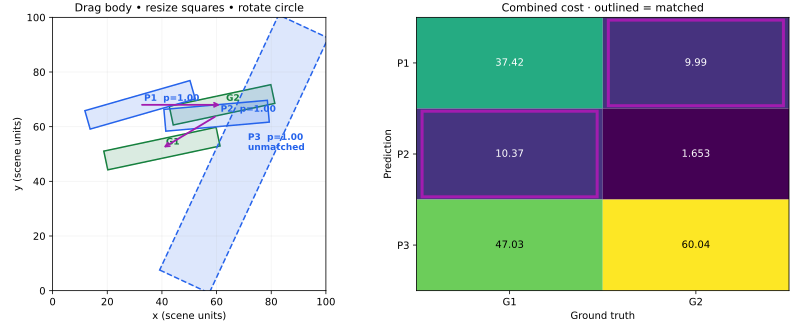

Metric,Raw,Cost,Weighted
L1,0.26,disabled,0
Rotated IoU,0,disabled,0
ProbIoU,6.19728e-05,disabled,0
Hausdorff,0.195765,disabled,0
KL P → GT,36.8516,disabled,0
KL GT → P,37.9917,disabled,0
Symmetric KL (mean),37.4217,37.4217,37.4217
Gaussian W2,17.9153,disabled,0
Bhattacharyya,8.9957,disabled,0
Hellinger,0.999938,disabled,0


In [6]:
import numpy as np

from ml_sandbox.matcher_lab import Box, NormalizedBox, box_to_gaussian, normalized_box_to_gaussian
from ml_sandbox.matcher_lab.gaussian_kl import symmetric_kl

converter_example = box_to_gaussian(Box("example", 0, 0, 12, 3))
np.testing.assert_allclose(converter_example.covariance, np.diag([12, 0.75]))
encoded_example = NormalizedBox("encoded", 0.25, 0.5, 0.1, 0.1, 0.7, 0.7)
physical_gaussian = normalized_box_to_gaussian(encoded_example, image_width=800, image_height=400)
np.testing.assert_allclose(physical_gaussian.mean, [200, 200])
np.testing.assert_allclose(physical_gaussian.covariance, [[1000 / 3, 200], [200, 1000 / 3]])

gaussian_scene = scenes["Oversized competing prediction"]
gaussian_config = MatcherConfig((CostTerm(Metric.SYMMETRIC_KL, 1.0),))
gaussian_evaluation = evaluate_costs(
    gaussian_scene.predictions, gaussian_scene.targets, gaussian_config
)
pred_gaussian = box_to_gaussian(gaussian_scene.predictions[0].box)
gt_gaussian = box_to_gaussian(gaussian_scene.targets[0])
assert np.isclose(gaussian_evaluation.total[0, 0], symmetric_kl(pred_gaussian, gt_gaussian))
display(SVG(static_preview(gaussian_scene, gaussian_config)))
display(HTML(pair_html(gaussian_scene, gaussian_config, gaussian_evaluation, "P1", "G1")))

## Method references

| Method | Primary reference | Relationship to this lab |
|---|---|---|
| Normalized L1 | Carion et al., **End-to-End Object Detection with Transformers** (ECCV 2020): [paper](https://arxiv.org/abs/2005.12872), [official matcher](https://github.com/facebookresearch/detr/blob/main/models/matcher.py) | Sum of absolute center/size errors. Configurable scene scales and the optional periodic angle term are lab adaptations. |
| Rotated IoU | [MMCV rotated IoU definition](https://mmcv.readthedocs.io/en/latest/api/generated/mmcv.ops.box_iou_rotated.html); Rezatofighi et al., **Generalized Intersection over Union** (CVPR 2019), [IoU definition](https://arxiv.org/abs/1902.09630) | Actual oriented-rectangle intersection/union, implemented here with polygon clipping. The lab uses Cartesian y-up coordinates and counterclockwise radians; convert conventions when comparing with image-coordinate libraries. GIoU itself is not implemented. |
| ProbIoU | Llerena et al., **Gaussian Bounding Boxes and Probabilistic Intersection-over-Union for Object Detection**: [2021 preprint](https://arxiv.org/abs/2106.06072), [TIP 2024 publication](https://doi.org/10.1109/TIP.2023.3348697) | Gaussian covariance from rotated dimensions; similarity is one minus Hellinger distance. |
| Gaussian Bhattacharyya distance | [ProbIoU paper, Gaussian distance derivation](https://arxiv.org/abs/2106.06072) | The unbounded distance underlying ProbIoU; also selectable directly as a geometry-only cost. |
| Gaussian KL, both directions | Yang et al., **Learning High-Precision Bounding Box for Rotated Object Detection via Kullback-Leibler Divergence** (NeurIPS 2021): [paper](https://proceedings.neurips.cc/paper_files/paper/2021/hash/98f13708210194c475687be6106a3b84-Abstract.html) | Closed-form Gaussian KL. The symmetric mean is a lab-defined comparison of both directions; no detection-loss transforms are applied. |
| Gaussian Wasserstein W2 | Yang et al., **Rethinking Rotated Object Detection with Gaussian Wasserstein Distance Loss** (ICML 2021): [paper](https://proceedings.mlr.press/v139/yang21l.html) | Raw unsquared W2, evaluated by factor alignment. The covariance convention is explicit and the paper's extra loss transforms are not reproduced. |
| Hellinger distance | [ProbIoU paper](https://arxiv.org/abs/2106.06072) | Unsquared Gaussian Hellinger, equal to one minus ProbIoU. |
| Sampled Hausdorff | Lee et al., **Hausdorff Distance Matching with Adaptive Query Denoising for Rotated Detection Transformer** (WACV 2025): [paper, §3.4 and appendix C](https://arxiv.org/html/2305.07598v5), [official RHINO cost](https://github.com/SIAnalytics/RHINO/blob/main/mmrotate/models/task_modules/assigners/match_cost.py) | Symmetric maximum nearest-point distance, with RHINO parameter normalization and 4/8/32 boundary samples. The standalone preset excludes the other RHINO costs and adaptive denoising. |
| Classification: negative log probability | [PyTorch negative log-likelihood definition](https://docs.pytorch.org/docs/stable/generated/torch.nn.NLLLoss.html); [official DETR matching classification cost](https://github.com/facebookresearch/detr/blob/main/models/matcher.py) | The lab deliberately uses `-log(max(p, epsilon))`. Original DETR matching uses `-p`; these are different formulations. |
| Rectangular assignment | [SciPy linear_sum_assignment](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html) | Reference solver, assigning exactly the smaller matrix dimension without implicit thresholds or dummy pairs. |

The selectable `1-S` and `-log(max(S, epsilon))` similarity-to-cost transforms are lab
analysis settings. They are not claimed to reproduce each paper's full matcher or training loss.
